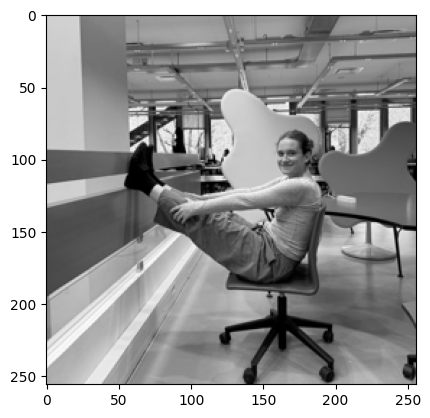

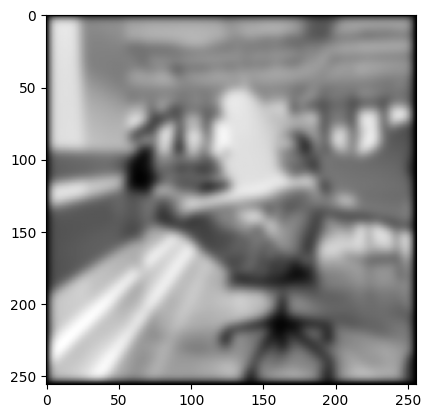

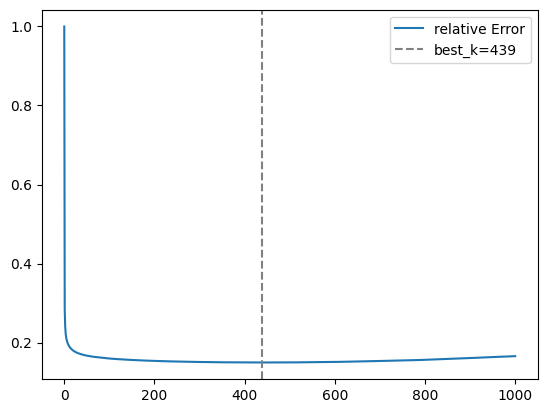

relativeError=0.14959237888044272 at index k=439


C:\Users\ansch\AppData\Local\Temp\ipykernel_22108\709009836.py:90: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


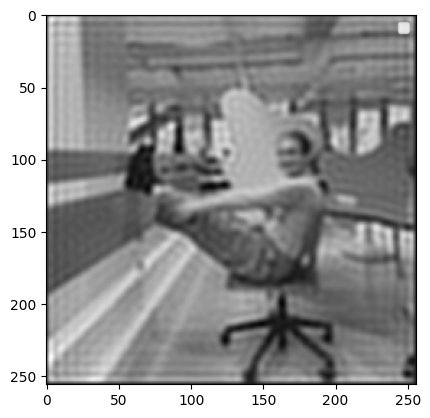

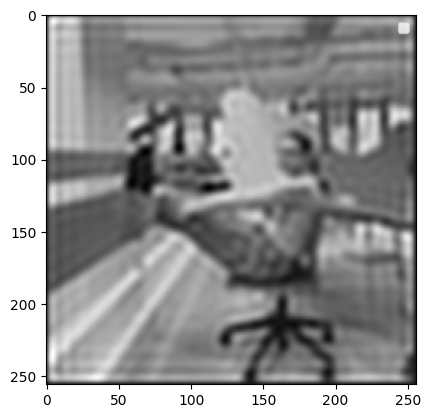

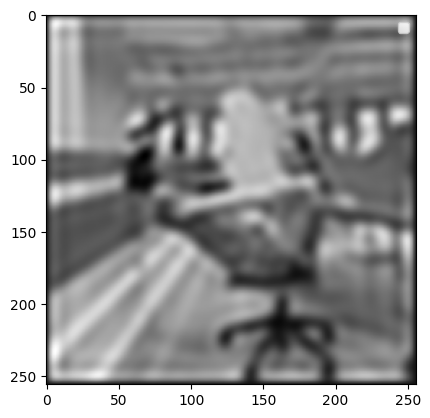

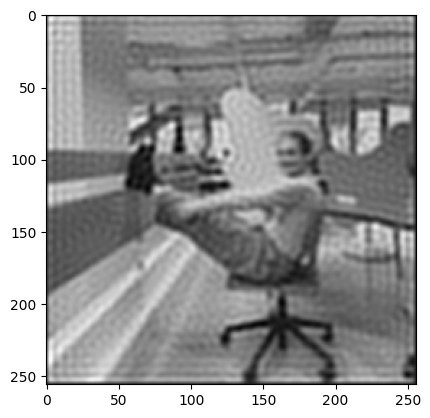

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dstn, idstn
from tkinter import Tk, filedialog

N = 256
T = 1e-3

from PIL import Image
from scipy.fft import dstn, idstn

# image with values in [0,1], black = 0 (crop your own photo to a square first)
im = Image.open('Lyapunov_Hannah.jpeg').convert('L')
X = np.asarray(im.resize((N, N)), float) / 255

plt.imshow(X,cmap="gray")
plt.show()
# forward operator A = S^T diag(lam) S, A^T = A
S = lambda x: dstn(x, type=2, norm='ortho')
ST = lambda x: idstn(x, type=2, norm='ortho')
k = np.arange(1, N + 1); lam = np.exp(-(k[:, None]**2 + k[None, :]**2) * T)
A = lambda x: ST(lam * S(x))

# we know that A.T = A
Y = A(X)

rng = np.random.default_rng(42)
e = rng.standard_normal(size=Y.shape)

e = e * 0.001 * np.linalg.norm(Y) / np.linalg.norm(e)

Ydelta = Y + e

# CGLS
iteration = 1000

xk = np.zeros_like(Ydelta)
rk_old = Ydelta.copy()
dk = A(rk_old)

relativeError = np.zeros(iteration+1)
relativeError[0] = 1.0
bestX = xk.copy()
bestk = 0

k_array = {5,20,200}
snapshots = {}

Xsolution_array = 0
minError = relativeError[0]
normX = np.linalg.norm(X)

for k in range(1,iteration+1):
    A_rk_old = A(rk_old)
    A_dk = A(dk)
    norm_A_rk_old = np.linalg.norm(A_rk_old)

    ak = norm_A_rk_old**2 / np.linalg.norm(A_dk)**2
    xk = xk + ak * dk

    rk_new = rk_old - ak * A_dk
    A_rk_new = A(rk_new)

    bk = np.linalg.norm(A_rk_new)**2 / norm_A_rk_old**2
    dk = A_rk_new + bk * dk

    rk_old = rk_new

    relativeError[k] = np.linalg.norm(X - xk) / normX
    if relativeError[k] < minError:
        minError = relativeError[k]
        bestX = xk.copy()
        bestk = k
    if k in k_array:
        snapshots[k] = xk.copy()
plt.imshow(Y,cmap="gray")
plt.show()


plt.plot(relativeError,label="relative Error")
plt.axvline(bestk,linestyle="--",color="grey",label=f"best_k={bestk}")
plt.legend()
plt.show()

print(f"relativeError={relativeError[bestk]} at index k={bestk}")

for k in k_array:
    plt.imshow(snapshots[k],cmap="gray",label=f"k={k}")
    plt.legend()
    plt.show()

plt.imshow(bestX,cmap="gray")
plt.show()

CGLS:   	|  relativeError_CGLS:	0.1632770003317595  	| k=61
Landweber:  	|  relativeError_LW:	0.16281385991503575  	| k=1000


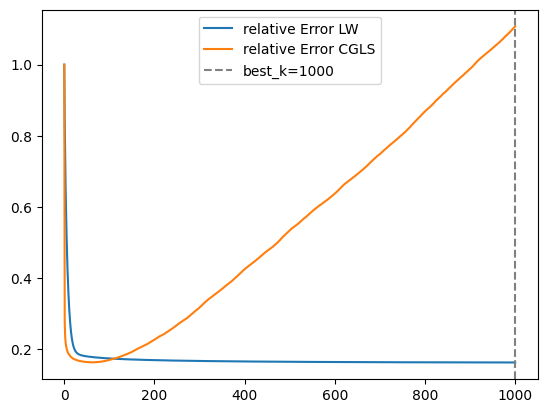

C:\Users\ansch\AppData\Local\Temp\ipykernel_22108\4174477950.py:74: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


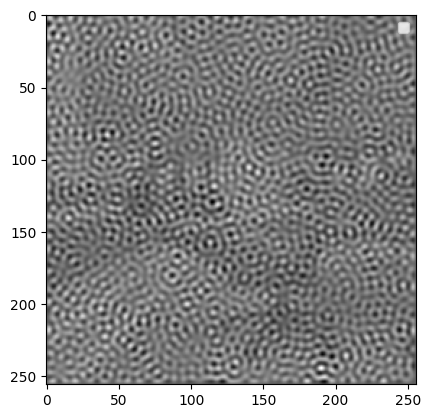

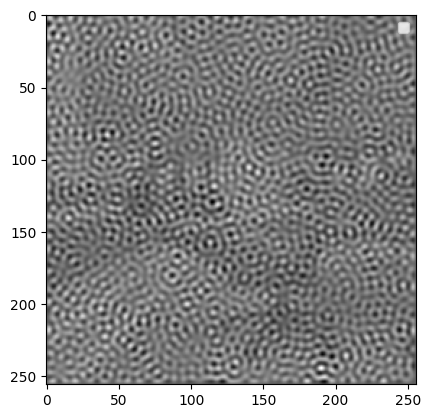

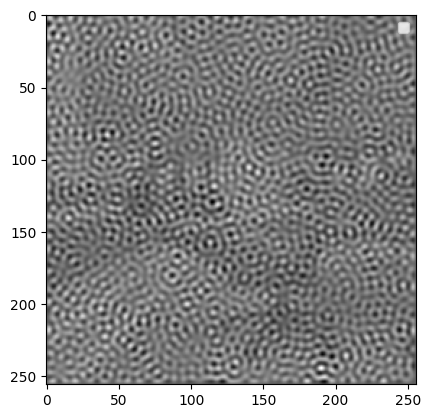

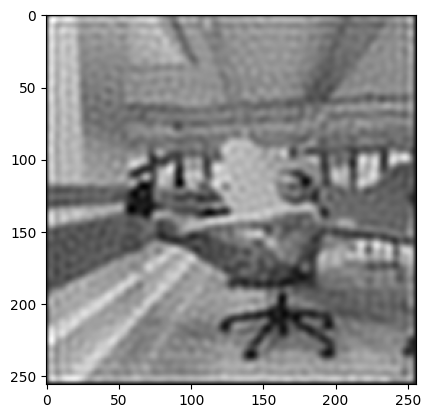

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dstn, idstn
from tkinter import Tk, filedialog

N = 256
T = 1e-3

from PIL import Image
from scipy.fft import dstn, idstn

# image with values in [0,1], black = 0 (crop your own photo to a square first)
im = Image.open('Lyapunov_Hannah.jpeg').convert('L')
X = np.asarray(im.resize((N, N)), float) / 255

# forward operator A = S^T diag(lam) S, A^T = A
S = lambda x: dstn(x, type=2, norm='ortho')
ST = lambda x: idstn(x, type=2, norm='ortho')
k = np.arange(1, N + 1); lam = np.exp(-(k[:, None]**2 + k[None, :]**2) * T)
A = lambda x: ST(lam * S(x))

# we know that A.T = A
Y = A(X)

# add NOISE
rng = np.random.default_rng(42)
e = rng.standard_normal(size=Y.shape)
e = e * 0.01 * np.linalg.norm(Y) / np.linalg.norm(e)
Ydelta = Y + e

# Landweber
iteration_LW = 1000

xk_LW = np.zeros_like(Ydelta)

normA = np.exp(-2*T)
omega = 1.9/normA**2

relativeError_LW = np.zeros(iteration+1)
relativeError_LW[0] = 1.0
bestX_LW = xk_LW.copy()
bestk_LW = 0

k_array = {5,20,200}
snapshots_LW = {}

minError_LW = relativeError_LW[0]
normX = np.linalg.norm(X)


for k in range(1,iteration+1):
    xk_LW = xk_LW - omega * A(A(xk_LW) - Ydelta)

    relativeError_LW[k] = np.linalg.norm(X - xk_LW) / normX
    if relativeError_LW[k] < minError_LW:
        minError_LW = relativeError_LW[k]
        bestX_LW = xk_LW.copy()
        bestk_LW = k
    if k in k_array:
        snapshots_LW[k] = xk.copy()

print(f"CGLS:   \t|  relativeError_CGLS:\t{relativeError[bestk]}  \t| k={bestk}")
print(f"Landweber:  \t|  relativeError_LW:\t{relativeError_LW[bestk_LW]}  \t| k={bestk_LW}")

plt.plot(relativeError_LW,label="relative Error LW")
plt.plot(relativeError,label="relative Error CGLS")
plt.axvline(bestk_LW,linestyle="--",color="grey",label=f"best_k={bestk_LW}")
plt.legend()
plt.show()

for k in k_array:
    plt.imshow(snapshots_LW[k],cmap="gray",label=f"k={k}")
    plt.legend()
    plt.show()

plt.imshow(bestX_LW,cmap="gray")
plt.show()

CGLS is faster and gets us a better solution